# Poroelastic radiation patterns — Yang et al. (2019) with `sweep`'s Biot

Yang et al. (2019) derived the single-parameter **radiation patterns** of a fluid-saturated porous rock: a
fast P wave hits a point perturbation of one rock property and scatters into fast P and S waves. They
compared four parameterizations of the same nine-parameter rock, low frequency (the slow P wave is
diffusive), and used the overlap of the patterns to judge which parameters a waveform inversion can
tell apart.

This notebook computes the same patterns **two ways** and overlays them:

* **Analytic** — the first-order Born scattering amplitude of the Biot equations `Biot` solves, chained
  to each rock parameter with exact (autograd) Jacobians. Pure numpy/torch, no wave simulation.
* **Numerical** — solve the Biot equations with `sweep`: an explosion above a point scatterer, the
  scattered field `forward(background + δm) − forward(background)` read off a ring of receivers.

| set | nine parameters |
|---|---|
| (K<sub>d</sub>, G) | K<sub>s</sub>, ρ<sub>s</sub>, **K<sub>d</sub>, G**, φ, κ<sub>0</sub>, K<sub>f</sub>, ρ<sub>f</sub>, η |
| (λ, μ) | K<sub>s</sub>, ρ<sub>s</sub>, **λ, μ** (drained), φ, κ<sub>0</sub>, K<sub>f</sub>, ρ<sub>f</sub>, η |
| (K<sub>s</sub>, G<sub>s</sub>) | **K<sub>s</sub>, G<sub>s</sub>**, ρ<sub>s</sub>, φ, κ<sub>0</sub>, **c<sub>s</sub>** (consolidation), K<sub>f</sub>, ρ<sub>f</sub>, η |
| (V<sub>P</sub>, V<sub>S</sub>) | **V<sub>P</sub>, V<sub>S</sub>** (grain velocities), ρ<sub>s</sub>, φ, κ<sub>0</sub>, c<sub>s</sub>, K<sub>f</sub>, ρ<sub>f</sub>, η |

Every pattern is drawn as in the paper: incident fast P travelling **down**, angle measured from the
**top** (the direction back toward the source), fast P in blue, S in red.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from sweep.equations import Biot, Elastic
from sweep.equations.biot import biot_from_rock, biot_fast_p_velocity
from sweep.propagator.torch import PropTorch
from sweep.signal import ricker
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False          # eager stencils in full FP32
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.9.1+cu128


## 1. Rock model and the four parameterizations

Table 3 of the paper, read in SI units (permeability in m², viscosity in Pa·s). `biot_from_rock` turns
the rock properties into the eight coefficients `Biot` takes, `[H, μ, C, M, ρ, ρ_f, m, b]`. The paper's
dynamic-permeability model tends, at low frequency, to a tortuosity of 1.25 (`m = 1.25 ρ_f/φ`) and a drag
`b = η/κ0`. Each parameterization is a map from its nine parameters to the same rock; all four must give
identical background coefficients.

For (K<sub>s</sub>, G<sub>s</sub>), `K_d = K_s(1−φ)/(1+c_sφ)` and `G = G_s(1−φ)/(1+2c_sφ/3)` (the form that
gives the paper's G = 9 GPa from G<sub>s</sub> = 13.33 GPa, c<sub>s</sub> = 5). For (V<sub>P</sub>,
V<sub>S</sub>), `K_d = (V_P² − 4V_S²/3)ρ_s`, `G = V_S²ρ_s`, and the grain modulus follows from
c<sub>s</sub>: `K_s = K_d(1+c_sφ)/(1−φ)`.

In [2]:
ROCK = dict(Ks=30e9, rhos=2700.0, Kd=18e9, G=9e9, phi=0.1, k0=1e-11, Kf=2.2e9, rhof=1040.0, eta=1e-3)
TORT, CS = 1.25, 5.0

def coefs(Ks, rhos, Kd, G, phi, k0, Kf, rhof, eta):
    # rock properties -> [H, mu, C, M, rho, rho_f, m, b]
    c = biot_from_rock(k_s=Ks, rho_s=rhos, k_f=Kf, rho_f=rhof, eta=eta, k_d=Kd, mu=G,
                       phi=phi, kappa=k0, tortuosity=TORT)
    return torch.stack(torch.broadcast_tensors(*[torch.as_tensor(x, dtype=torch.float64) for x in c]))

def kd_g(Ks, rhos, Kd, G, phi, k0, Kf, rhof, eta):
    return coefs(Ks, rhos, Kd, G, phi, k0, Kf, rhof, eta)
def lam_mu(Ks, rhos, lam, mu, phi, k0, Kf, rhof, eta):
    return coefs(Ks, rhos, lam + 2*mu/3, mu, phi, k0, Kf, rhof, eta)
def ks_gs(Ks, Gs, rhos, phi, k0, cs, Kf, rhof, eta):
    return coefs(Ks, rhos, Ks*(1-phi)/(1+cs*phi), Gs*(1-phi)/(1+2*cs*phi/3), phi, k0, Kf, rhof, eta)
def vp_vs(VP, VS, rhos, phi, k0, cs, Kf, rhof, eta):
    kd = (VP**2 - 4*VS**2/3)*rhos
    return coefs(kd*(1+cs*phi)/(1-phi), rhos, kd, VS**2*rhos, phi, k0, Kf, rhof, eta)

r = ROCK
SETS = {   # name: (map, {parameter: background value})
    "(Kd, G)": (kd_g, dict(Ks=r["Ks"], rhos=r["rhos"], Kd=r["Kd"], G=r["G"], phi=r["phi"], k0=r["k0"],
                           Kf=r["Kf"], rhof=r["rhof"], eta=r["eta"])),
    "(λ, μ)": (lam_mu, dict(Ks=r["Ks"], rhos=r["rhos"], lam=r["Kd"] - 2*r["G"]/3, mu=r["G"], phi=r["phi"],
                            k0=r["k0"], Kf=r["Kf"], rhof=r["rhof"], eta=r["eta"])),
    "(Ks, Gs)": (ks_gs, dict(Ks=r["Ks"], Gs=r["G"]*(1 + 2*CS*r["phi"]/3)/(1 - r["phi"]), rhos=r["rhos"],
                             phi=r["phi"], k0=r["k0"], cs=CS, Kf=r["Kf"], rhof=r["rhof"], eta=r["eta"])),
    "(VP, VS)": (vp_vs, dict(VP=np.sqrt((r["Kd"] + 4*r["G"]/3)/r["rhos"]), VS=np.sqrt(r["G"]/r["rhos"]),
                             rhos=r["rhos"], phi=r["phi"], k0=r["k0"], cs=CS, Kf=r["Kf"], rhof=r["rhof"],
                             eta=r["eta"])),
}

def evaluate(name, values):
    fn, base = SETS[name]
    return fn(**{k: torch.as_tensor(v, dtype=torch.float64) for k, v in values.items()})

C0 = evaluate("(Kd, G)", SETS["(Kd, G)"][1])
for name, (fn, base) in SETS.items():
    assert torch.allclose(evaluate(name, base), C0, rtol=1e-12), name
H, MU, C, M, RHO, RHOF, MF, B = C0.tolist()
print("background  H = %.3f  mu = %.3f  C = %.3f  M = %.3f GPa   rho = %.1f  rho_f = %.0f  m = %.0f kg/m3   b = eta/k0 = %.1e Pa s/m2"
      % (H/1e9, MU/1e9, C/1e9, M/1e9, RHO, RHOF, MF, B))
print("all four parameterizations give these coefficients:", ", ".join(SETS))
F0 = 15.0                                            # Ricker peak frequency of the simulation
wB = r["eta"]*r["phi"]/(r["rhof"]*r["k0"])           # Biot characteristic frequency
D = (r["k0"]/r["eta"])*(H*M - C*C)/H                 # pore-pressure diffusivity
print("f_B = %.0f Hz, f0/f_B = %.4f; slow P is diffusive: diffusion length sqrt(2D/w) = %.2f m at %g Hz"
      % (wB/2/np.pi, F0/(wB/2/np.pi), np.sqrt(2*D/(2*np.pi*F0)), F0))

background  H = 32.885  mu = 9.000  C = 7.213  M = 18.033 GPa   rho = 2534.0  rho_f = 1040  m = 13000 kg/m3   b = eta/k0 = 1.0e+08 Pa s/m2
all four parameterizations give these coefficients: (Kd, G), (λ, μ), (Ks, Gs), (VP, VS)
f_B = 1530 Hz, f0/f_B = 0.0098; slow P is diffusive: diffusion length sqrt(2D/w) = 1.87 m at 15 Hz


## 2. Analytic — first-order Born scattering

`Biot` solves, with solid displacement **u** and relative fluid displacement **w** (q = ∂ₜ**w**),

`ρ ü + ρ_f ẅ = ∇·σ`,  `ρ_f ü + m ẅ + b ẇ = −∇p`,
`σ = (H−2μ)(∇·u) I + 2μ ε(u) + C(∇·w) I`,  `p = −C ∇·u − M ∇·w`.

At frequency ω the drag is an imaginary fluid mass, `m̃ = m + i b/ω`. Each wave mode has a two-component
amplitude `a = (a_u, a_w)`: fast P solves `[[H, C],[C, M]] a = V² [[ρ, ρ_f],[ρ_f, m̃]] a`, S has
`a = (1, −ρ_f/m̃)` and `V_S² = μ/(ρ − ρ_f²/m̃)`. A point perturbation δ of the eight coefficients scatters an
incident mode `a` (direction **q̂**, polarization **p̂**) into a mode `b` (direction **r̂**, polarization **ĝ**)
with amplitude

`S = ω² [δρ a_u b_u + δρ_f (a_u b_w + a_w b_u) + δm̃ a_w b_w] (p̂·ĝ)`
` − k_a k_b { [(δH−2δμ) a_u b_u + δC (a_u b_w + a_w b_u) + δM a_w b_w] (p̂·q̂)(ĝ·r̂) + δμ a_u b_u [(p̂·ĝ)(q̂·r̂) + (p̂·r̂)(q̂·ĝ)] }`,

the elastic Born amplitude with two-component polarizations. The far-field solid motion is `S b_u / D_b`
times the 2-D Green's function, with `D = aᵀ[[H, C],[C, M]]a` for P and `D = μ` for S. A rock parameter
reaches the eight coefficients through the parameterization's map; its Jacobian is computed exactly with
autograd.

In [3]:
W0 = 2*np.pi*F0

def modes(c, w=W0):
    H, mu, C, M, rho, rhof, m, b = [float(x) for x in c]
    mt = m + 1j*b/w                                   # exp(-i w t): drag = imaginary fluid mass
    K = np.array([[H, C], [C, M]]); R = np.array([[rho, rhof], [rhof, mt]])
    ev, vec = np.linalg.eig(np.linalg.solve(R, K))
    i = int(np.argmax(ev.real))
    aP = vec[:, i]/vec[0, i]
    return dict(K=K, mu=mu, w=w, VP=np.sqrt(ev[i]), aP=aP, VS=np.sqrt(mu/(rho - rhof**2/mt)), aS=np.array([1.0, -rhof/mt]))

def born(dc, th, md):
    # far-field solid amplitude (fast P along r, S along theta) scattered by dc = delta[H, mu, C, M, rho, rho_f, m, b]
    # for a unit fast P travelling down (+z); th = scattering angle from forward; common factors dropped
    dH, dmu, dC, dM, drho, drf, dm, db = [float(x) for x in dc]
    w, a = md["w"], md["aP"]
    dmt = dm + 1j*db/w
    kP, kS = w/md["VP"], w/md["VS"]
    r = np.stack([np.sin(th), np.cos(th)])           # scattered direction (x, z)
    out = []
    for g, bm, k, Dm in ((r, a, kP, a @ md["K"] @ a), (np.stack([np.cos(th), -np.sin(th)]), md["aS"], kS, md["mu"])):
        pg, gr, qr = g[1], (g*r).sum(0), r[1]            # p = q = z
        inert = w*w*(drho*a[0]*bm[0] + drf*(a[0]*bm[1] + a[1]*bm[0]) + dmt*a[1]*bm[1])*pg
        stiff = ((dH - 2*dmu)*a[0]*bm[0] + dC*(a[0]*bm[1] + a[1]*bm[0]) + dM*a[1]*bm[1])*gr \
                + dmu*a[0]*bm[0]*2*pg*qr
        out.append((inert - kP*k*stiff)*bm[0]/Dm/np.sqrt(k))
    return out

MD0 = modes(C0)
VFP, VS = 1/np.real(1/MD0["VP"]), 1/np.real(1/MD0["VS"])
print("low-frequency speeds: fast P %.1f m/s, S %.1f m/s;  fast-P fluid amplitude |a_w| = %.1e"
      % (VFP, VS, abs(MD0["aP"][1])))
print("Gassmann check: sqrt(H/rho) = %.1f, sqrt(mu/rho) = %.1f m/s" % (np.sqrt(H/RHO), np.sqrt(MU/RHO)))

EPS = 0.10                                            # the paper's 10 % perturbations
def jacobian(name):
    fn, base = SETS[name]
    keys = list(base)
    p0 = torch.tensor([float(base[k]) for k in keys], dtype=torch.float64)
    J = torch.autograd.functional.jacobian(lambda p: fn(**dict(zip(keys, p))), p0)
    return keys, p0.numpy(), J.numpy()

DC = {}                                               # (set, parameter) -> delta of the 8 coefficients
for name in SETS:
    keys, p0, J = jacobian(name)
    for i, k in enumerate(keys):
        DC[(name, k)] = J[:, i]*EPS*p0[i]

TH = np.radians(np.arange(360.0))                     # scattering angle from forward
ref = np.abs(born(DC[("(Kd, G)", "Kd")], TH, MD0)[0]).max()
print("\n%-9s %-5s %26s %10s" % ("set", "param", "fast P  fwd / side / back", "S max"))
for (name, k), dc in DC.items():
    P, S = (np.abs(x)/ref for x in born(dc, TH, MD0))
    print("%-9s %-5s %8.3f %8.3f %8.3f %10.3f" % (name, k, P[0], P[90], P[180], S.max()))

low-frequency speeds: fast P 3602.4 m/s, S 1884.6 m/s;  fast-P fluid amplitude |a_w| = 4.6e-04
Gassmann check: sqrt(H/rho) = 3602.4, sqrt(mu/rho) = 1884.6 m/s

set       param  fast P  fwd / side / back      S max
(Kd, G)   Ks       0.783    0.783    0.783      0.000
(Kd, G)   rhos     3.037    0.000    3.037      8.025
(Kd, G)   Kd       1.000    1.000    1.000      0.000
(Kd, G)   G        1.156    0.578    1.156      4.378
(Kd, G)   phi      0.004    0.211    0.418      0.548
(Kd, G)   k0       0.000    0.000    0.000      0.002
(Kd, G)   Kf       0.228    0.228    0.228      0.000
(Kd, G)   rhof     0.130    0.000    0.130      0.343
(Kd, G)   eta      0.000    0.000    0.000      0.002
(λ, μ)    Ks       0.783    0.783    0.783      0.000
(λ, μ)    rhos     3.037    0.000    3.037      8.025
(λ, μ)    lam      0.667    0.667    0.667      0.000
(λ, μ)    mu       1.489    0.244    1.489      4.378
(λ, μ)    phi      0.004    0.211    0.418      0.548
(λ, μ)    k0       0.000    0.

The table gives each pattern for a 10 % perturbation, relative to the fast-P amplitude of K<sub>d</sub>
(forward = along the incident wave, back = toward the source). At these frequencies the rock is deep in
the low-frequency regime: the fast P wave carries almost no relative fluid motion (|a_w| ≈ 5·10⁻⁴), so
δC, δM and δm̃ hardly scatter it, and η and κ₀ (which only enter through b) scatter three to four orders
of magnitude less than the moduli.

## 3. Numerical — solve the Biot equations with `sweep`

A homogeneous rock, an explosion (total-stress source) 2 km above a point scatterer, and 360 receivers on
a ring of radius 1.6 km (6–13 wavelengths, the far field) recording the solid velocity. Each rock
parameter is perturbed by 10 % in a Gaussian blob of σ = 5 m (a point compared with the 240 m fast-P
wavelength) and mapped to the eight coefficients cell by cell. The scattered fast P is the radial
velocity in a window around its arrival, the scattered S the tangential velocity in its own window.

In [4]:
N, DH, DT, ABCN = 520, 10.0, 1e-3, 40
CX = CZ = 260
SRC_UP, R, NREC, SIG, DELAY = 200, 160, 360, 0.5, 0.08
T_PP = (SRC_UP + R)*DH/VFP + DELAY                     # fast P in, fast P out
T_PS = SRC_UP*DH/VFP + R*DH/VS + DELAY                 # fast P in, S out
NT = int((T_PS + 0.2)/DT)
TT = np.arange(NT)*DT
WIN_PP, WIN_PS = np.abs(TT - T_PP) < 0.09, np.abs(TT - T_PS) < 0.09
PSI = np.radians(np.arange(NREC)*360.0/NREC)          # receiver azimuth from the top (toward the source)
RX = np.round(CX - R*np.sin(PSI)).astype(int)
RZ = np.round(CZ - R*np.cos(PSI)).astype(int)
RHAT = np.stack([-np.sin(PSI), -np.cos(PSI)], 1)      # radial    -> fast P
THAT = np.stack([-np.cos(PSI), np.sin(PSI)], 1)       # tangential -> S
TH_RING = PSI + np.pi                                  # scattering angle from forward
SRC = np.array([[CX, CZ - SRC_UP]])
RECV = np.concatenate([np.stack([RX, RZ], 1), [[CX, CZ]]])[None]   # ring + one receiver on the scatterer
WAV = torch.from_numpy(ricker(TT - DELAY, f=F0))
zz, xx = np.mgrid[0:N, 0:N]
BLOB = torch.from_numpy(np.exp(-((xx - CX)**2 + (zz - CZ)**2)/(2*SIG**2)))
VMAX = biot_fast_p_velocity(C0.tolist())
print(f"grid {N}x{N}, dh {DH} m, dt {DT} s, nt {NT};  fast P ~{T_PP:.2f} s, S ~{T_PS:.2f} s on the ring;"
      f"  CFL {VMAX*DT/DH:.2f} (inviscid fast P {VMAX:.0f} m/s)")

def models(name=None, k=None, eps=EPS):
    # eight coefficient arrays: the background, or parameter k of set `name` times (1 + eps * blob)
    if name is None:
        return [torch.full((N, N), float(c), dtype=torch.float32, device=DEV) for c in C0]
    fn, base = SETS[name]
    vals = {kk: (torch.as_tensor(float(v), dtype=torch.float64)*(1 + eps*BLOB) if kk == k
                 else torch.as_tensor(float(v), dtype=torch.float64)) for kk, v in base.items()}
    return [c.expand(N, N).to(torch.float32).to(DEV) for c in fn(**vals)]

prop = PropTorch(Biot(spatial_order=4, device=DEV), shape=(N, N), source_type=["sxx", "szz"],
                 receiver_type=["vx", "vz"], abcn=ABCN, dh=DH, dt=DT, nt=NT, device=DEV,
                 backend="torch", impl="eager")

def run(ms, p=prop):
    with torch.no_grad():
        rec = p(WAV, SRC.copy(), RECV.copy(), models=ms, max_vel=VMAX, pml_freq=F0)
    return rec[0].double().cpu().numpy()                # (nt, nrec + 1, 2)

def rings(du):
    ring = du[:, :NREC]
    vr = ring[..., 0]*RHAT[None, :, 0] + ring[..., 1]*RHAT[None, :, 1]
    vt = ring[..., 0]*THAT[None, :, 0] + ring[..., 1]*THAT[None, :, 1]
    return np.sqrt((vr[WIN_PP]**2).mean(0)), np.sqrt((vt[WIN_PS]**2).mean(0))

RUNS = [("(Kd, G)", k) for k in ("Kd", "G", "rhos", "phi", "Ks", "Kf", "rhof")] \
     + [("(λ, μ)", k) for k in ("lam", "mu")] \
     + [("(Ks, Gs)", k) for k in ("Ks", "Gs", "phi", "cs")] \
     + [("(VP, VS)", k) for k in ("VP", "VS", "rhos", "phi", "cs")]
t0 = time.time()
U0 = run(models())
NUM = {}
for name, k in RUNS:
    NUM[(name, k)] = rings(run(models(name, k)) - U0)
NUM_LIN = rings(run(models("(Kd, G)", "phi", eps=0.01)) - U0)    # linearity: 1 % instead of 10 %
print(f"{len(RUNS) + 2} Biot runs in {time.time() - t0:.0f} s")

grid 520x520, dh 10.0 m, dt 0.001 s, nt 1684;  fast P ~1.08 s, S ~1.48 s on the ring;  CFL 0.36 (inviscid fast P 3617 m/s)


sweep: compiling the eager time step with torch.compile; the first forward/backward pass takes longer (seconds to a few minutes, once per grid size, cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


20 Biot runs in 25 s


## 4. (K<sub>d</sub>, G) — the paper's Figure 1

The numerical curves (solid) against the analytic ones (dotted). A scatterer of finite size σ weakens
large-angle scattering by the form factor `exp(−|k_in − k_out|²σ²/2)`; the analytic curves include it, with
the effective wavenumber of the broadband wavelet fitted once on the isotropic K<sub>d</sub> circle. One
global scale, also fitted on K<sub>d</sub>, maps the analytic amplitudes onto the numerical ones for every
panel, so the relative sizes of all patterns are tested too. Each panel is scaled to its own maximum; the
corner number is that maximum relative to the fast P of K<sub>d</sub>.

broadband effective frequency 20.3 Hz (alpha = 1.35)
(Kd, G)   Kd    fast P: isotropic: std/mean 0.003 max num/ana 1.003 |  S: S/P 0.002      max num/ana   -  
(Kd, G)   G     fast P: corr 0.9992              max num/ana 0.963 |  S: corr 0.9993    max num/ana 0.927
(Kd, G)   rhos  fast P: corr 0.9999              max num/ana 1.008 |  S: corr 0.9997    max num/ana 0.980
(Kd, G)   phi   fast P: corr 0.9999              max num/ana 0.959 |  S: corr 0.9997    max num/ana 0.972
(Kd, G)   Ks    fast P: isotropic: std/mean 0.003 max num/ana 0.967 |  S: S/P 0.003      max num/ana   -  
(Kd, G)   Kf    fast P: isotropic: std/mean 0.003 max num/ana 0.985 |  S: S/P 0.010      max num/ana   -  
(Kd, G)   rhof  fast P: corr 0.9999              max num/ana 1.003 |  S: corr 0.9997    max num/ana 0.972
(λ, μ)    lam   fast P: isotropic: std/mean 0.003 max num/ana 1.003 |  S: S/P 0.003      max num/ana   -  
(λ, μ)    mu    fast P: corr 0.9992              max num/ana 0.968 |  S: corr 0.9992    max num

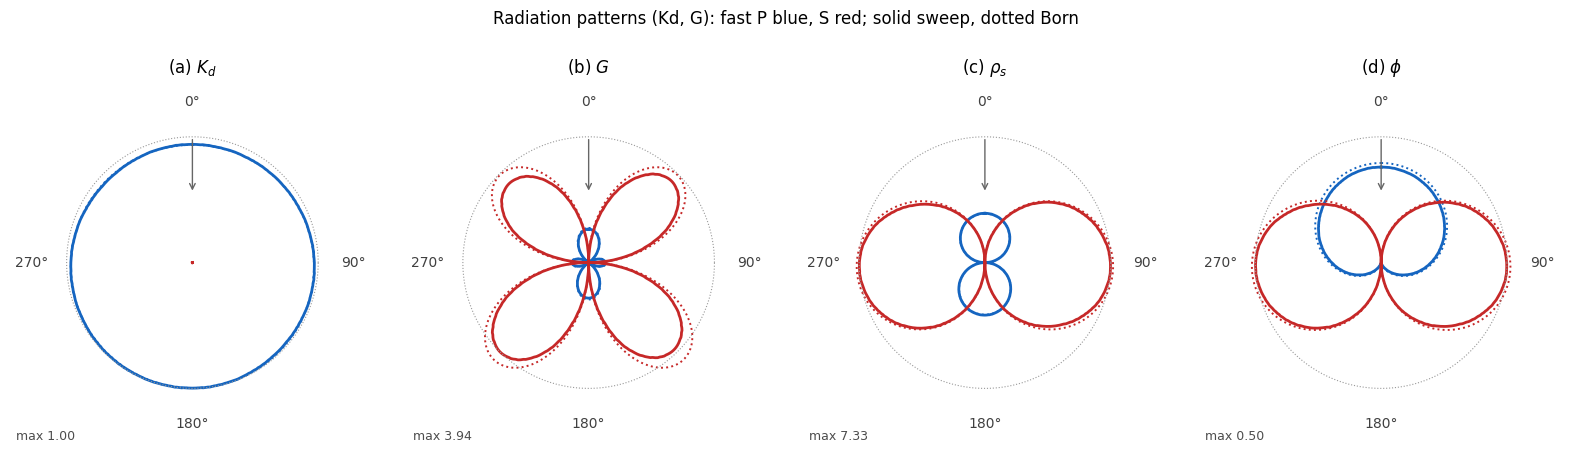

In [5]:
SIG_M = SIG*DH
kP0, kS0 = W0/VFP, W0/VS
_slope = np.polyfit(np.cos(PSI/2)**2, np.log(NUM[("(Kd, G)", "Kd")][0]), 1)[0]
ALPHA = float(np.sqrt(max(-_slope/(2*kP0**2*SIG_M**2), 1e-6)))     # broadband k_eff = ALPHA * k(F0)
aP, aS = ALPHA*kP0, ALPHA*kS0
FF_PP = np.exp(-2*aP**2*np.cos(PSI/2)**2*SIG_M**2)
FF_PS = np.exp(-(aP**2 + aS**2 + 2*aP*aS*np.cos(PSI))*SIG_M**2/2)

RAW = {key: born(dc, TH_RING, MD0) for key, dc in DC.items()}          # point-scatterer Born
ANA = {key: (np.abs(p)*FF_PP, np.abs(s)*FF_PS) for key, (p, s) in RAW.items()}
num0, ana0 = NUM[("(Kd, G)", "Kd")][0], ANA[("(Kd, G)", "Kd")][0]
SCALE = (num0*ana0).sum()/(ana0*ana0).sum()                          # one global scale
REF = SCALE*np.abs(born(DC[("(Kd, G)", "Kd")], TH_RING, MD0)[0]).max()
BAND = (PSI < np.radians(140)) | (PSI > np.radians(220))            # leave out +-40 deg around forward

def corr(a, b):
    a, b = a[BAND], b[BAND]
    return np.nan if np.std(b) < 1e-3*np.mean(b) else np.corrcoef(a, b)[0, 1]

def report(key):
    (nP, nS), (aP_, aS_) = NUM[key], ANA[key]
    aP_, aS_ = SCALE*aP_, SCALE*aS_
    rawP = np.abs(RAW[key][0]); iso = np.std(rawP) < 1e-3*np.mean(rawP)
    shape_p = ("isotropic: std/mean %.3f" % (np.std(nP/FF_PP)/np.mean(nP/FF_PP))) if iso else ("corr %.4f" % corr(nP, aP_))
    shape_s = ("S/P %.3f" % (nS.max()/nP.max())) if aS_.max() < 1e-3*aP_.max() else ("corr %.4f" % corr(nS, aS_))
    print("%-9s %-5s fast P: %-24s max num/ana %.3f |  S: %-14s max num/ana %s"
          % (key[0], key[1], shape_p, nP.max()/aP_.max(), shape_s,
             "%.3f" % (nS.max()/aS_.max()) if aS_.max() >= 1e-3*aP_.max() else "  -  "))
print(f"broadband effective frequency {ALPHA*F0:.1f} Hz (alpha = {ALPHA:.2f})")
for key in NUM:
    report(key)

def frame(ax, title):
    ax.set_aspect("equal"); ax.axis("off")
    t = np.linspace(0, 2*np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), ":", color="0.6", lw=0.8)
    for ang in (0, 90, 180, 270):
        a = np.radians(ang)
        ax.text(1.28*np.sin(a), 1.28*np.cos(a), f"{ang}°", ha="center", va="center", fontsize=10, color="0.25")
    ax.annotate("", xy=(0, 0.55), xytext=(0, 1.0), arrowprops=dict(arrowstyle="->", color="0.4"))
    ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); ax.set_title(title, fontsize=12)

def curve(ax, r, scale, color, ls, lw):
    a = np.append(PSI, PSI[0]); rr = np.append(r, r[0])/scale
    ax.plot(rr*np.sin(a), rr*np.cos(a), ls, color=color, lw=lw)    # drawn clockwise from the top

def polar(ax, key, title):
    (nP, nS), (aP_, aS_) = NUM[key], ANA[key]
    top = max(nP.max(), nS.max())
    curve(ax, nP, top, "#1565C0", "-", 2.0); curve(ax, SCALE*aP_, top, "#1565C0", ":", 1.4)
    curve(ax, nS, top, "#C62828", "-", 2.0); curve(ax, SCALE*aS_, top, "#C62828", ":", 1.4)
    frame(ax, title)
    ax.text(-1.4, -1.4, f"max {top/REF:.2f}", fontsize=9, color="0.3")

fig, axs = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, (k, lab) in zip(axs, [("Kd", "(a) $K_d$"), ("G", "(b) $G$"), ("rhos", r"(c) $\rho_s$"), ("phi", r"(d) $\phi$")]):
    polar(ax, ("(Kd, G)", k), lab)
fig.suptitle("Radiation patterns (Kd, G): fast P blue, S red; solid sweep, dotted Born", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

**Linearity.** The patterns are first-order (Born) quantities; a 1 % perturbation of φ, scaled by ten,
should give the same ring as the 10 % one.

In [6]:
n10, n1 = NUM[("(Kd, G)", "phi")][0], 10*NUM_LIN[0]
print(f"phi (Kd, G), fast P: max |10 x ring(1 %) - ring(10 %)| / max = {np.abs(n1 - n10).max()/n10.max():.3f},"
      f"  corr = {np.corrcoef(n1, n10)[0, 1]:.4f}")

phi (Kd, G), fast P: max |10 x ring(1 %) - ring(10 %)| / max = 0.057,  corr = 0.9999


## 5. Scattered wavefields — the paper's Figure 2

The same four perturbations, now as snapshots of the scattered solid velocity |**v**| (as the paper
shows), when the scattered fast P has travelled 1 km. The outer ring is fast P, the inner ring S. Ring
brightness against angle is the radiation pattern; the analytic |R| is drawn in green around each ring.

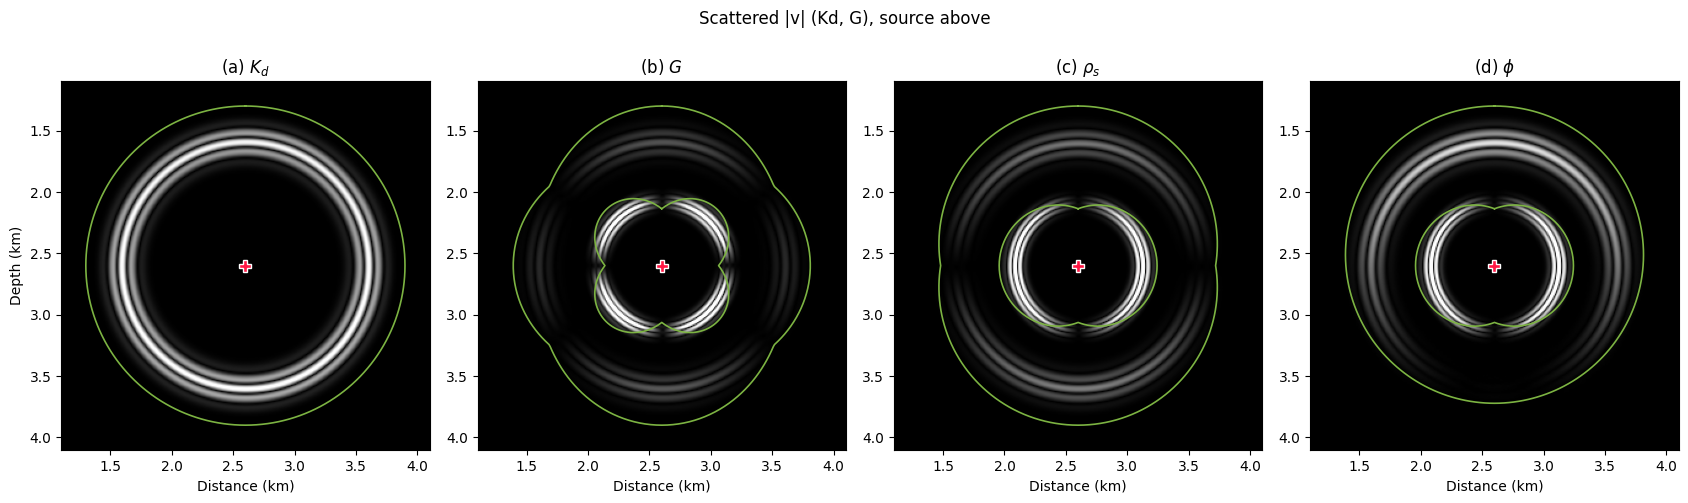

In [7]:
R_SNAP = 100
IT = int(round((SRC_UP + R_SNAP)*DH/VFP/DT + DELAY/DT))
R_S_SNAP = R_SNAP*VS/VFP
prop_snap = PropTorch(Biot(spatial_order=4, device=DEV), shape=(N, N), source_type=["sxx", "szz"],
                      receiver_type=["vx", "vz"], abcn=ABCN, dh=DH, dt=DT, nt=IT + 1, device=DEV,
                      backend="torch", impl="eager", use_ckpt=False)

def snapshot(ms):
    with torch.no_grad():
        _, sn = prop_snap(WAV[:IT + 1], SRC.copy(), RECV.copy(), models=ms, max_vel=VMAX, pml_freq=F0,
                          return_wavefield=True, snapshot_times=[IT])
    names = list(prop_snap.wavefield_names)
    z0, x0 = prop_snap.pad[0], prop_snap.pad[2]
    return sn[0, [names.index("vx"), names.index("vz")], 0, 0, z0:z0 + N, x0:x0 + N].double().cpu().numpy()

S0 = snapshot(models())
HW = 150                                             # half-width of the displayed window (cells)
ext = np.array([CX - HW, CX + HW, CZ + HW, CZ - HW])*DH/1000
fig, axs = plt.subplots(1, 4, figsize=(17, 4.7))
for ax, (k, lab) in zip(axs, [("Kd", "(a) $K_d$"), ("G", "(b) $G$"), ("rhos", r"(c) $\rho_s$"), ("phi", r"(d) $\phi$")]):
    dv = snapshot(models("(Kd, G)", k)) - S0
    a = np.hypot(dv[0], dv[1])[CZ - HW:CZ + HW, CX - HW:CX + HW]
    ax.imshow(a, extent=ext, cmap="gray", vmin=0, vmax=np.percentile(a, 99.5))
    p, s = (np.abs(x) for x in born(DC[("(Kd, G)", k)], TH_RING, MD0))
    for amp, base in ((p, R_SNAP + 12), (s, R_S_SNAP - 6)):
        if amp.max() < 1e-2*max(p.max(), s.max()):
            continue                                         # this mode is not scattered
        rad = (base + 18*amp/amp.max())*DH/1000
        aa = np.append(PSI, PSI[0]); rad = np.append(rad, rad[0])
        ax.plot(CX*DH/1000 - rad*np.sin(aa), CZ*DH/1000 - rad*np.cos(aa), color="#7CB342", lw=1.2)
    ax.plot(CX*DH/1000, CZ*DH/1000, "P", color="#FF1744", ms=9, mec="w")
    ax.set_title(lab, fontsize=12); ax.set_xlabel("Distance (km)")
axs[0].set_ylabel("Depth (km)")
fig.suptitle("Scattered |v| (Kd, G), source above", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

## 6. The other parameterizations — the paper's Figures 3–5

λ and μ are the drained Lamé constants (K<sub>d</sub> = λ + 2μ/3, G = μ); in (K<sub>s</sub>, G<sub>s</sub>)
the frame moduli follow from the grain moduli and c<sub>s</sub>; in (V<sub>P</sub>, V<sub>S</sub>) the
grain velocities fix K<sub>d</sub> and G with ρ<sub>s</sub>. The same parameter name can scatter very
differently from one set to the next, because the other eight parameters are held fixed.

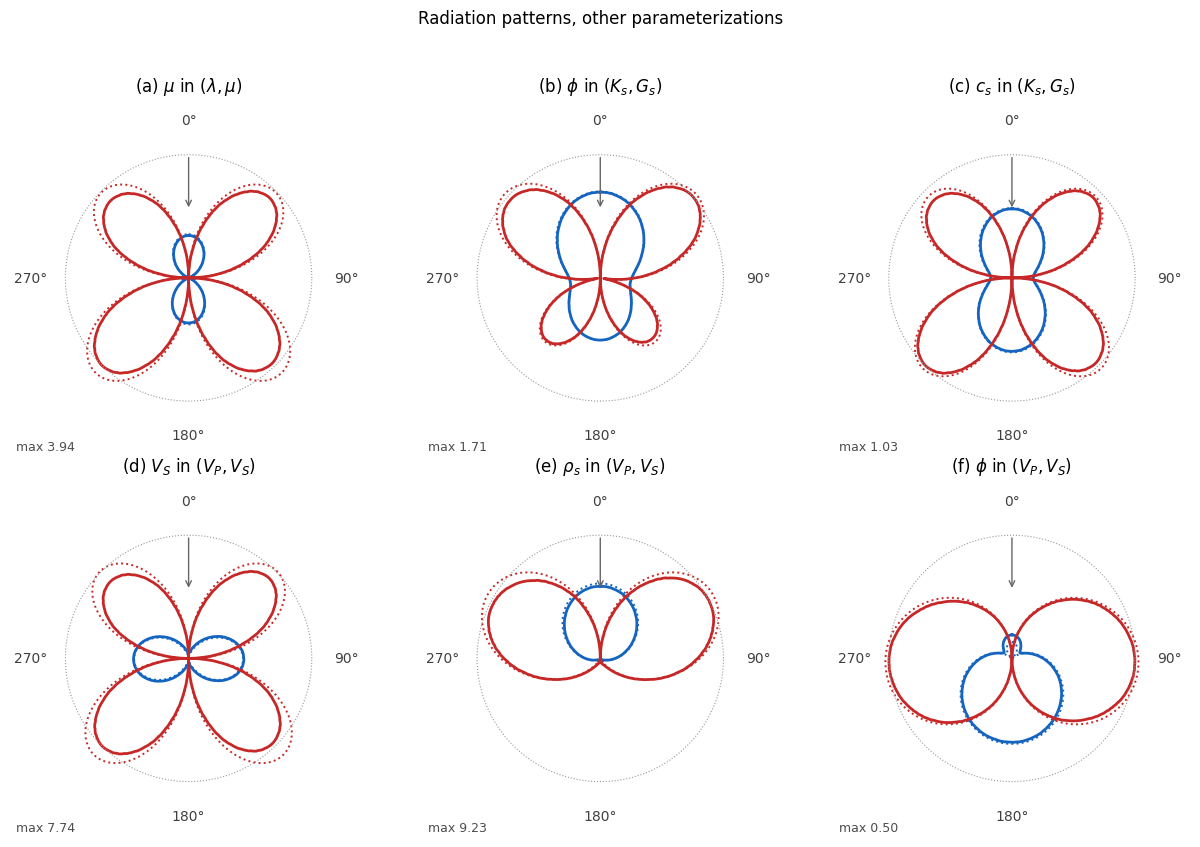

In [8]:
PANELS = [(("(λ, μ)", "mu"), r"(a) $\mu$ in $(\lambda,\mu)$"),
          (("(Ks, Gs)", "phi"), r"(b) $\phi$ in $(K_s,G_s)$"),
          (("(Ks, Gs)", "cs"), r"(c) $c_s$ in $(K_s,G_s)$"),
          (("(VP, VS)", "VS"), r"(d) $V_S$ in $(V_P,V_S)$"),
          (("(VP, VS)", "rhos"), r"(e) $\rho_s$ in $(V_P,V_S)$"),
          (("(VP, VS)", "phi"), r"(f) $\phi$ in $(V_P,V_S)$")]
fig, axs = plt.subplots(2, 3, figsize=(12.5, 8.6))
for ax, (key, lab) in zip(axs.ravel(), PANELS):
    polar(ax, key, lab)
fig.suptitle("Radiation patterns, other parameterizations", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

## 7. Why the patterns look elastic — the low-frequency (Gassmann) limit

With a negligible fluid amplitude in the fast P wave, the scattering only sees the undrained modulus H,
the shear modulus μ and the bulk density ρ: the Biot rock scatters like an elastic solid with
`V_P² = H/ρ`, `V_S² = μ/ρ`. Each rock parameter's pattern is then the elastic Born pattern of its
(δH, δμ, δρ). Below, the same experiments with `sweep`'s `Elastic` (those velocities and density, cell
by cell) against the Biot rings, and the scattering strength of all nine (K<sub>d</sub>, G) parameters
from the analytic amplitude.

incident |vz| at the scatterer: Biot / Elastic = 0.9961


(Kd, G)   G      Biot vs Elastic rings: fast P rel. diff 0.005, S rel. diff 0.036


(Kd, G)   phi    Biot vs Elastic rings: fast P rel. diff 0.005, S rel. diff 0.037


(λ, μ)    mu     Biot vs Elastic rings: fast P rel. diff 0.005, S rel. diff 0.036


(VP, VS)  rhos   Biot vs Elastic rings: fast P rel. diff 0.005, S rel. diff 0.036


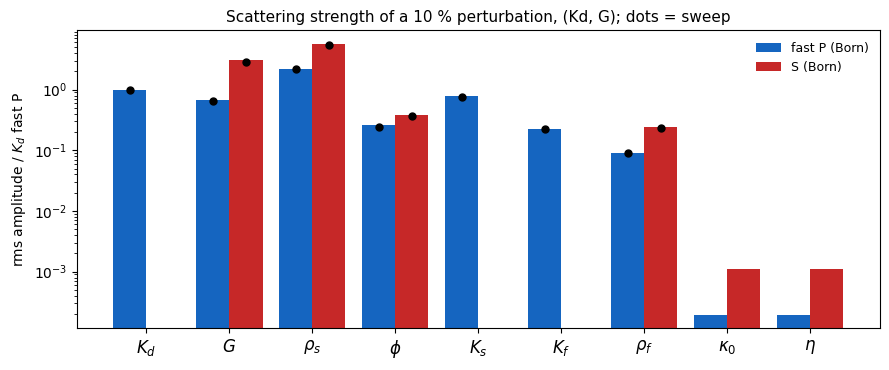

In [9]:
def elastic_models(ms):
    h, mu, rho = (m.double() for m in (ms[0], ms[1], ms[4]))
    return [torch.sqrt(h/rho).float(), torch.sqrt(mu/rho).float(), rho.float()]

prop_el = PropTorch(Elastic(spatial_order=4, device=DEV), shape=(N, N), source_type=["sxx", "szz"],
                    receiver_type=["vx", "vz"], abcn=ABCN, dh=DH, dt=DT, nt=NT, device=DEV,
                    backend="torch", impl="eager")
E0 = run(elastic_models(models()), prop_el)
inc_b = np.abs(U0[:, NREC, 1]).max(); inc_e = np.abs(E0[:, NREC, 1]).max()
print("incident |vz| at the scatterer: Biot / Elastic = %.4f" % (inc_b/inc_e))
for key in [("(Kd, G)", "G"), ("(Kd, G)", "phi"), ("(λ, μ)", "mu"), ("(VP, VS)", "rhos")]:
    nb_p, nb_s = NUM[key]
    ne_p, ne_s = rings((run(elastic_models(models(*key)), prop_el) - E0)*inc_b/inc_e)
    print("%-9s %-5s  Biot vs Elastic rings: fast P rel. diff %.3f, S rel. diff %.3f"
          % (key[0], key[1], np.linalg.norm(nb_p - ne_p)/np.linalg.norm(nb_p), np.linalg.norm(nb_s - ne_s)/np.linalg.norm(nb_s)))

labels = ["Kd", "G", "rhos", "phi", "Ks", "Kf", "rhof", "k0", "eta"]
strength = np.array([[np.sqrt(np.mean(np.abs(x)**2)) for x in born(DC[("(Kd, G)", k)], TH, MD0)] for k in labels])/ref
fig, ax = plt.subplots(figsize=(9, 3.8))
xx_ = np.arange(len(labels))
ax.bar(xx_ - 0.2, strength[:, 0], 0.4, color="#1565C0", label="fast P (Born)")
ax.bar(xx_ + 0.2, strength[:, 1], 0.4, color="#C62828", label="S (Born)")
for i, k in enumerate(labels):
    if ("(Kd, G)", k) in NUM:                              # sweep, where the Born amplitude is measurable
        nP, nS = NUM[("(Kd, G)", k)]
        for x0, n, ff, ana in ((i - 0.2, nP, FF_PP, strength[i, 0]), (i + 0.2, nS, FF_PS, strength[i, 1])):
            if ana > 1e-2:
                ax.plot(x0, np.sqrt(np.mean(n**2))/REF/np.sqrt(np.mean(ff**2)), "o", color="k", ms=5)
ax.set_yscale("log"); ax.set_xticks(xx_)
ax.set_xticklabels([r"$K_d$", r"$G$", r"$\rho_s$", r"$\phi$", r"$K_s$", r"$K_f$", r"$\rho_f$", r"$\kappa_0$", r"$\eta$"], fontsize=12)
ax.set_ylabel("rms amplitude / $K_d$ fast P"); ax.legend(fontsize=9, frameon=False)
ax.set_title("Scattering strength of a 10 % perturbation, (Kd, G); dots = sweep", fontsize=11)
fig.tight_layout(); plt.show()

## Notes

* **Analytic and numerical agree.** The printed correlations and amplitude ratios compare the
  first-order Born patterns with the `sweep` simulation, for every parameter that scatters measurably.
* **Low frequency makes the rock elastic for scattering.** The fast P wave moves the fluid with the
  frame, so only the undrained modulus, the shear modulus and the bulk density are seen; permeability and
  viscosity scatter 10³–10⁴ times weaker than the moduli and share the density pattern.
* **The parameterization decides the overlap.** A parameter's pattern is that of its (δH, δμ, δρ), which
  depends on what the other eight parameters hold fixed — φ in (K<sub>d</sub>, G) is nearly a pure
  impedance perturbation (no forward scattering), φ in (V<sub>P</sub>, V<sub>S</sub>) scatters mostly
  forward.

## Reference

Yang, Q., Malcolm, A., Rusmanugroho, H., & Mao, W. (2019). Analysis of radiation patterns for optimized full waveform inversion in fluid-saturated porous media. *Geophysical Journal International, 216*(3), 1919–1937. [doi:10.1093/gji/ggy525](https://doi.org/10.1093/gji/ggy525) — the rock, the four parameterizations and the single-parameter radiation patterns reproduced here.